In [13]:
import glob
import os

import torch
from torchvision import transforms
import numpy as np
import cv2
from PIL import Image
from torchvision.io import read_image
import matplotlib.pyplot as plt
from tqdm import tqdm

from v1.infer_unet import CustomMNasNetUnetInvResDec, filter_and_draw_bounding_boxes, mean1, std1, height, width, bin_threshold, min_area

import sys
sys.path.append("../../code/researches/objectdetectionmetrics/")
from metricsevaluator import MetricsEvaluator

In [2]:
class Model:
    def __init__(self, weights="MNAS_Unet.pth"):
        self.model = CustomMNasNetUnetInvResDec(1, 1)
        self.model.load_state_dict(torch.load(weights, map_location='cpu'))

        pytorch_total_params = sum(p.numel() for p in self.model.parameters())
        pytorch_total_traineble_params = sum(p.numel() for p in self.model.parameters() if p.requires_grad)
        print(pytorch_total_params, pytorch_total_traineble_params)
        
        self.test_composed_transform1 = transforms.Compose([
            transforms.Grayscale(),
            transforms.Resize((height, width), antialias=True),
            transforms.Normalize(mean=[mean1], std=[std1])
        ])
    
    def predict(self, img_path):
        modelin = self.test_composed_transform1(read_image(img_path).float())[None]
        
        output = self.model(modelin)
        output_sig = torch.sigmoid(output)
        binarized = torch.where(output_sig < bin_threshold, torch.tensor(0), torch.tensor(255))
        predicted_mask_np = binarized.squeeze(0).cpu().numpy().squeeze(0)
        
        original_with_bb_np = modelin * 255
        original_with_bb_np = original_with_bb_np.squeeze(0).cpu().numpy().squeeze(0)
        predicted_mask_with_bb_np = np.copy(predicted_mask_np)

        foot_points_predicted, bounding_boxes_predicted, predicted_mask_with_bb_np, predicted_mask_np, original_with_bb_np = \
            filter_and_draw_bounding_boxes(
                predicted_mask_with_bb_np, original_with_bb_np, min_area)
        
        result = []
        for p in foot_points_predicted:
            x, y = p
            x = x / width
            y = y / height
            result.append([x, y])
        
        return result

In [8]:
tst_labels_pths = sorted(glob.glob("../ultralytics/datasets/position_db_pose/labels/test/*.txt"))
len(tst_labels_pths)

490

In [9]:
tst_img_paths = sorted(glob.glob("../ultralytics/datasets/position_db_pose/images/test/*.jpg"))
len(tst_img_paths)

490

In [4]:
model = Model()

2478393 2478393


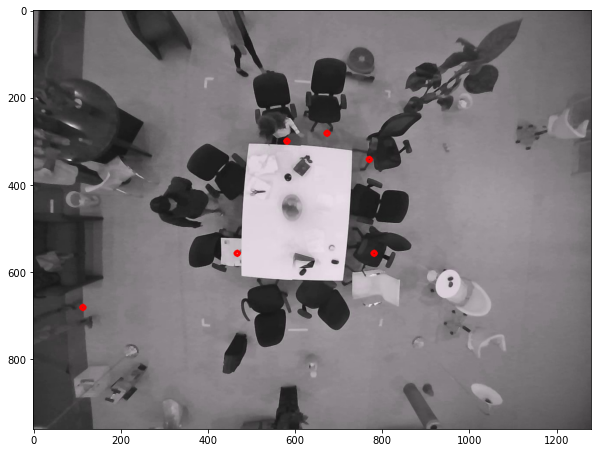

In [35]:
idx = 0
img = cv2.imread(tst_img_paths[idx])

points = model.predict(tst_img_paths[idx])

tmp = img.copy()
h, w, _ = tmp.shape
for p in points:
    x, y = p
    x = int(x * w)
    y = int(y * h)
    cv2.circle(tmp, (x, y), 5, (255, 0, 0), 5)

plt.figure(figsize=(10, 10))
plt.imshow(tmp)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 490/490 [00:23<00:00, 20.65it/s]

P = 0.796. R = 0.782. F1 = 0.789. AP = 0.633


Text(0, 0.5, 'precision')

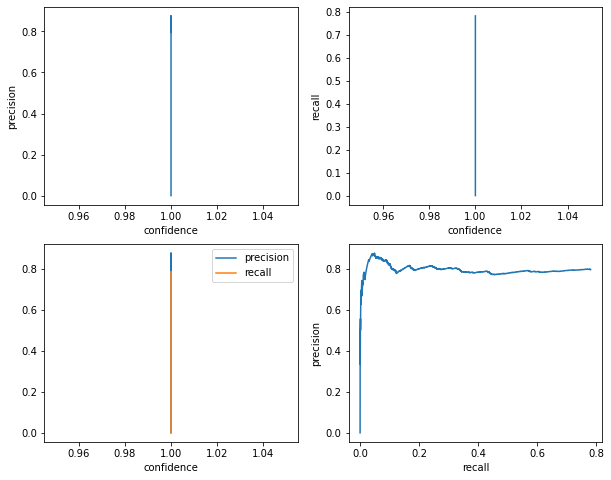

In [36]:
# positions

CONF_TH = 0.25
H = 0.05
W = 0.05 * 0.75

# init evaluator
evaluator = MetricsEvaluator(
    is_relative_coordinates=True,
    is_xywh_coordinates=True,
    img_size=(1280, 960)
)

for label_pth in tst_labels_pths:
    img_name = os.path.basename(label_pth).split(".")[0]

    with open(label_pth, "rt") as f:
        lines = f.readlines()
    
    for line in lines:
        _, x_c, y_c, w, h, x_p, y_p = [float(i) for i in line[:-1].split()] 
        x = x_c - w / 2
        y = y_c - h / 2
        
        evaluator.add_gt_box(
            img_path=img_name,
            class_name="person",
            bbox=[x_p - W // 2, y_p - H // 2, W, H]
        )
    # break

for img_pth in tqdm(tst_img_paths):
    img_name = os.path.basename(img_pth).split(".")[0]
    res = model.predict(img_pth)
    for p in res:
        evaluator.add_det_box(
            img_path=img_name,
            class_name="person",
            bbox=[p[0] - W // 2, p[1] - H // 2, W, H],
            confidence=1
        )
    # break

result = evaluator.eval_conf_vals(0.005)[0]

precision = result["total TP"] / (result["total TP"] + result["total FP"])
recall = result["total TP"] / (result["total positives"])

f_score = 2 * precision * recall / (precision + recall)
print(f"P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")

plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.plot(result["confidence"], result["precision"])
plt.xlabel("confidence")
plt.ylabel("precision")

plt.subplot(2, 2, 2)
plt.plot(result["confidence"], result["recall"])
plt.xlabel("confidence")
plt.ylabel("recall")

plt.subplot(2, 2, 3)
plt.plot(result["confidence"], result["precision"], label="precision")
plt.plot(result["confidence"], result["recall"], label="recall")
# plt.title("exp5")
# plt.vlines(0.11, 0, 1, label="0.11", colors="r")

plt.xlabel("confidence")
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(result["recall"], result["precision"])
plt.xlabel("recall")
plt.ylabel("precision")


In [38]:
result['total positives'], result['total TP'], result['total FP']

(4023, 3145.0, 808.0)

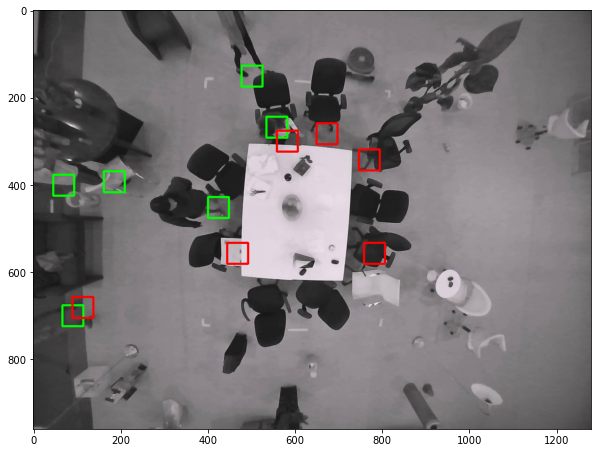

In [34]:
tmp = cv2.imread(img_pth)
for box in evaluator._all_bounding_boxes._boundingBoxes:
    if box._bbType.value == 1:
        c = (0, 255, 0)
    else:
        c = (255, 0, 0)
    
    cv2.rectangle(tmp, (box._x, box._y), (box._x2, box._y2), c, 3)

plt.figure(figsize=(10, 10))
plt.imshow(tmp)

In [27]:
box._x

535